In [1]:
import pandas as pd
df = pd.read_csv("data/heart_disease.csv")
print(df.shape)


(10000, 21)


# Heart Disease Prediction

**Problem:** ...
**Why it matters:** ...
**Type of problem:** ...

What do we predict? (whether a patient has heart disease)
Why is it interesting? (early detection, prevention, saving lives)
What type of problem? Classification (binary, 2 classes), not regression, because the output is a category (Yes/No), not a number.


In [2]:
df.shape

(10000, 21)

In [3]:
df.head()


,Age,Gender,Blood Pressure,Cholesterol Level,Exercise Habits,Smoking,Family Heart Disease,Diabetes,BMI,High Blood Pressure,...,High LDL Cholesterol,Alcohol Consumption,Stress Level,Sleep Hours,Sugar Consumption,Triglyceride Level,Fasting Blood Sugar,CRP Level,Homocysteine Level,Heart Disease Status
0,56.0,Male,153.0,155.0,High,Yes,Yes,No,24.991591,Yes,...,No,High,Medium,7.633228,Medium,342.0,NaN,12.969246,12.387250,No
1,69.0,Female,146.0,286.0,High,No,Yes,Yes,25.221799,No,...,No,Medium,High,8.744034,Medium,133.0,157.0,9.355389,19.298875,No
2,46.0,Male,126.0,216.0,Low,No,No,No,29.855447,No,...,Yes,Low,Low,4.440440,Low,393.0,92.0,12.709873,11.230926,No
3,32.0,Female,122.0,293.0,High,Yes,Yes,No,24.130477,Yes,...,Yes,Low,High,5.249405,High,293.0,94.0,12.509046,5.961958,No
4,60.0,Male,166.0,242.0,Low,Yes,Yes,Yes,20.486289,Yes,...,No,Low,High,7.030971,High,263.0,154.0,10.381259,8.153887,No


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Age                   9971 non-null   float64
 1   Gender                9981 non-null   str    
 2   Blood Pressure        9981 non-null   float64
 3   Cholesterol Level     9970 non-null   float64
 4   Exercise Habits       9975 non-null   str    
 5   Smoking               9975 non-null   str    
 6   Family Heart Disease  9979 non-null   str    
 7   Diabetes              9970 non-null   str    
 8   BMI                   9978 non-null   float64
 9   High Blood Pressure   9974 non-null   str    
 10  Low HDL Cholesterol   9975 non-null   str    
 11  High LDL Cholesterol  9974 non-null   str    
 12  Alcohol Consumption   7414 non-null   str    
 13  Stress Level          9978 non-null   str    
 14  Sleep Hours           9975 non-null   float64
 15  Sugar Consumption     9970 non-

In [5]:
df.describe()

,Age,Blood Pressure,Cholesterol Level,BMI,Sleep Hours,Triglyceride Level,Fasting Blood Sugar,CRP Level,Homocysteine Level
count,9971.000000,9981.000000,9970.000000,9978.000000,9975.000000,9974.000000,9978.000000,9974.000000,9980.000000
mean,49.296259,149.757740,225.425577,29.077269,6.991329,250.734409,120.142213,7.472201,12.456271
std,18.193970,17.572969,43.575809,6.307098,1.753195,87.067226,23.584011,4.340248,4.323426
min,18.000000,120.000000,150.000000,18.002837,4.000605,100.000000,80.000000,0.003647,5.000236
25%,34.000000,134.000000,187.000000,23.658075,5.449866,176.000000,99.000000,3.674126,8.723334
50%,49.000000,150.000000,226.000000,29.079492,7.003252,250.000000,120.000000,7.472164,12.409395
75%,65.000000,165.000000,263.000000,34.520015,8.531577,326.000000,141.000000,11.255592,16.140564
max,80.000000,180.000000,300.000000,39.996954,9.999952,400.000000,160.000000,14.997087,19.999037


In [6]:
df.describe(include="all")

,Age,Gender,Blood Pressure,Cholesterol Level,Exercise Habits,Smoking,Family Heart Disease,Diabetes,BMI,High Blood Pressure,...,High LDL Cholesterol,Alcohol Consumption,Stress Level,Sleep Hours,Sugar Consumption,Triglyceride Level,Fasting Blood Sugar,CRP Level,Homocysteine Level,Heart Disease Status
count,9971.000000,9981,9981.000000,9970.000000,9975,9975,9979,9970,9978.000000,9974,...,9974,7414,9978,9975.000000,9970,9974.000000,9978.000000,9974.000000,9980.000000,10000
unique,NaN,2,NaN,NaN,3,2,2,2,NaN,2,...,2,3,3,NaN,3,NaN,NaN,NaN,NaN,2
top,NaN,Male,NaN,NaN,High,Yes,No,No,NaN,Yes,...,No,Medium,Medium,NaN,Low,NaN,NaN,NaN,NaN,No
freq,NaN,5003,NaN,NaN,3372,5123,5004,5018,NaN,5022,...,5036,2500,3387,NaN,3390,NaN,NaN,NaN,NaN,8000
mean,49.296259,NaN,149.757740,225.425577,NaN,NaN,NaN,NaN,29.077269,NaN,...,NaN,NaN,NaN,6.991329,NaN,250.734409,120.142213,7.472201,12.456271,NaN
std,18.193970,NaN,17.572969,43.575809,NaN,NaN,NaN,NaN,6.307098,NaN,...,NaN,NaN,NaN,1.753195,NaN,87.067226,23.584011,4.340248,4.323426,NaN
min,18.000000,NaN,120.000000,150.000000,NaN,NaN,NaN,NaN,18.002837,NaN,...,NaN,NaN,NaN,4.000605,NaN,100.000000,80.000000,0.003647,5.000236,NaN
25%,34.000000,NaN,134.000000,187.000000,NaN,NaN,NaN,NaN,23.658075,NaN,...,NaN,NaN,NaN,5.449866,NaN,176.000000,99.000000,3.674126,8.723334,NaN
50%,49.000000,NaN,150.000000,226.000000,NaN,NaN,NaN,NaN,29.079492,NaN,...,NaN,NaN,NaN,7.003252,NaN,250.000000,120.000000,7.472164,12.409395,NaN
75%,65.000000,NaN,165.000000,263.000000,NaN,NaN,NaN,NaN,34.520015,NaN,...,NaN,NaN,NaN,8.531577,NaN,326.000000,141.000000,11.255592,16.140564,NaN


In [7]:
for col in df.select_dtypes(exclude="number").columns:
    print(col, df[col].unique())

Gender <ArrowStringArray>
['Male', 'Female', nan]
Length: 3, dtype: str
Exercise Habits <ArrowStringArray>
['High', 'Low', 'Medium', nan]
Length: 4, dtype: str
Smoking <ArrowStringArray>
['Yes', 'No', nan]
Length: 3, dtype: str
Family Heart Disease <ArrowStringArray>
['Yes', 'No', nan]
Length: 3, dtype: str
Diabetes <ArrowStringArray>
['No', 'Yes', nan]
Length: 3, dtype: str
High Blood Pressure <ArrowStringArray>
['Yes', 'No', nan]
Length: 3, dtype: str
Low HDL Cholesterol <ArrowStringArray>
['Yes', 'No', nan]
Length: 3, dtype: str
High LDL Cholesterol <ArrowStringArray>
['No', 'Yes', nan]
Length: 3, dtype: str
Alcohol Consumption <ArrowStringArray>
['High', 'Medium', 'Low', nan]
Length: 4, dtype: str
Stress Level <ArrowStringArray>
['Medium', 'High', 'Low', nan]
Length: 4, dtype: str
Sugar Consumption <ArrowStringArray>
['Medium', 'Low', 'High', nan]
Length: 4, dtype: str
Heart Disease Status <ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str


In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.isna().sum()

Age                       29
Gender                    19
Blood Pressure            19
Cholesterol Level         30
Exercise Habits           25
Smoking                   25
Family Heart Disease      21
Diabetes                  30
BMI                       22
High Blood Pressure       26
Low HDL Cholesterol       25
High LDL Cholesterol      26
Alcohol Consumption     2586
Stress Level              22
Sleep Hours               25
Sugar Consumption         30
Triglyceride Level        26
Fasting Blood Sugar       22
CRP Level                 26
Homocysteine Level        20
Heart Disease Status       0
dtype: int64

In [10]:
(df.isna().mean() * 100).round(1)

Age                      0.3
Gender                   0.2
Blood Pressure           0.2
Cholesterol Level        0.3
Exercise Habits          0.2
Smoking                  0.2
Family Heart Disease     0.2
Diabetes                 0.3
BMI                      0.2
High Blood Pressure      0.3
Low HDL Cholesterol      0.2
High LDL Cholesterol     0.3
Alcohol Consumption     25.9
Stress Level             0.2
Sleep Hours              0.2
Sugar Consumption        0.3
Triglyceride Level       0.3
Fasting Blood Sugar      0.2
CRP Level                0.3
Homocysteine Level       0.2
Heart Disease Status     0.0
dtype: float64

In [11]:
df["Heart Disease Status"].value_counts()

Heart Disease Status
No     8000
Yes    2000
Name: count, dtype: int64

In [12]:
df["Heart Disease Status"].value_counts(normalize=True)

Heart Disease Status
No     0.8
Yes    0.2
Name: proportion, dtype: float64

Matplotlib is building the font cache; this may take a moment.


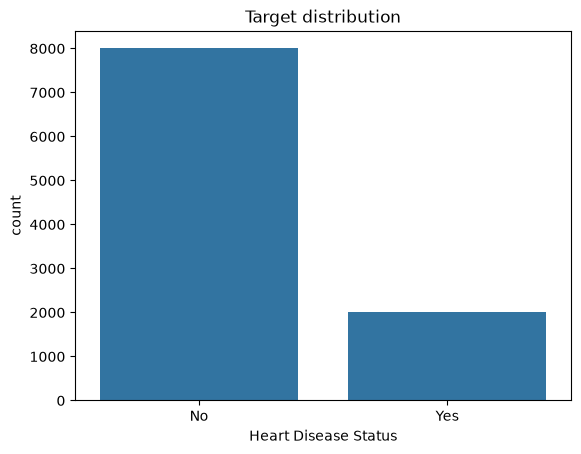

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.countplot(x=df["Heart Disease Status"])
plt.title("Target distribution")
plt.show()

| Column | Type | Meaning |
|---|---|---|
| Age | numeric | ... |
| Gender | categorical | ... |
| Blood Pressure | numeric | ... |
| Cholesterol Level | numeric | ... |
| Exercise Habits | categorical (Low/Medium/High) | ... |
| Smoking | yes/no | ... |
| Family Heart Disease | yes/no | ... |
| Diabetes | yes/no | ... |
| BMI | numeric | ... |
| High Blood Pressure | yes/no | ... |
| Low HDL Cholesterol | yes/no | ... |
| High LDL Cholesterol | yes/no | ... |
| Alcohol Consumption | categorical (Low/Medium/High) | ... |
| Stress Level | categorical (Low/Medium/High) | ... |
| Sleep Hours | numeric | ... |
| Sugar Consumption | categorical (Low/Medium/High) | ... |
| Triglyceride Level | numeric | ... |
| Fasting Blood Sugar | numeric | ... |
| CRP Level | numeric | ... |
| Homocysteine Level | numeric | ... |
| Heart Disease Status | yes/no (TARGET) | ... |

**Demographics:** Age, Gender
**Lifestyle:** Exercise, Smoking, Alcohol, Stress, Sleep, Sugar
**Medical history:** Family history, Diabetes, High blood pressure
**Blood tests / measures:** Blood pressure, Cholesterol, BMI, HDL, LDL, Triglycerides, Fasting blood sugar, CRP, Homocysteine
**Target:** Heart Disease Status

**Source:** Kaggle, "Heart Disease" by Oktay Ördekçi
https://www.kaggle.com/datasets/oktayrdeki/heart-disease